# Taller adicional. Clasificación difusa del movimiento de un robot
**Inteligencia Computacional Aplicada, Maestría en Ciencias de la Información y las Comunicaciones, UDFJC**

Sergio Santiago Duarte Rojas, código 20261595002

**Punto de partida.** Este taller sigue al taller propuesto, donde el clasificador de Wang y Mendel con etiquetas uniformes se aplicó a Wine. De ese taller se toman cinco decisiones. Todo lo que define el modelo (cortes, etiquetas, consecuentes y elección entre modelos) se calcula solo con el entrenamiento, y la prueba se mide una vez al final. La t-norma es el producto, porque allí el mínimo y el producto dieron las mismas decisiones con la regla más fuerte. Con tres etiquetas, tres de los cuatro errores de aquel taller caían en celdas dominadas por otro cultivar y uno en la única regla cuyo consecuente, tomado del registro de mayor grado, no seguía a la mayoría, y con más etiquetas aparecían celdas casi vacías. Por eso aquí el consecuente sale de la suma de fuerzas de todos los registros y se revisa el soporte de cada regla. Como allí, el modelo se compara con un árbol con el mismo límite de hojas, y las reglas se prueban también como Sugeno de orden cero, el tipo de sistema que se ajustó con ANFIS.

## Paso 0. Preparar el entorno
Las mismas librerías, la misma semilla y la misma función `verificar` del cuaderno resuelto, más pandas para leer los CSV.

In [1]:
# ---- Preparación del entorno ----
import random, time, itertools
import numpy as np
import matplotlib.pyplot as plt

try:
    import skfuzzy as fuzz
    from skfuzzy import control as ctrl
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-fuzzy"], check=False)
    import skfuzzy as fuzz
    from skfuzzy import control as ctrl

SEMILLA = 42
def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s)
fijar_semilla()
print("NumPy", np.__version__, "| scikit-fuzzy", fuzz.__version__)

def verificar(nombre, ok, pista=""):
    """Punto de control: imprime [OK] o [REVISAR] con una pista."""
    print(("[OK]      " if ok else "[REVISAR] ") + nombre + ("" if ok else "  ->  " + pista))
    return ok

import pandas as pd, os, json

NumPy 2.4.6 | scikit-fuzzy 0.5.0


## Paso 1. Funciones del cuaderno resuelto
Las funciones de pertenencia y el clasificador de Wang y Mendel con partición uniforme, que aquí sirve de punto de comparación.

In [2]:
# ---- Funciones de pertenencia (mismos parámetros que en MATLAB) ----
def trimf(x, a, b, c):
    """Triangular [a b c]."""
    x = np.asarray(x, dtype=float)
    izq = np.ones_like(x) if b == a else (x - a) / (b - a)
    der = np.ones_like(x) if c == b else (c - x) / (c - b)
    return np.clip(np.minimum(izq, der), 0.0, 1.0)

def trapmf(x, a, b, c, d):
    """Trapezoidal [a b c d]."""
    x = np.asarray(x, dtype=float)
    izq = np.ones_like(x) if b == a else (x - a) / (b - a)
    der = np.ones_like(x) if d == c else (d - x) / (d - c)
    return np.clip(np.minimum(np.minimum(izq, 1.0), der), 0.0, 1.0)

def gaussmf(x, sigma, c):
    """Gaussiana [sigma c] (el orden de MATLAB: primero sigma, luego el centro)."""
    x = np.asarray(x, dtype=float)
    return np.exp(-((x - c) ** 2) / (2.0 * sigma ** 2))

_MF = {"trimf": trimf, "trapmf": trapmf, "gaussmf": gaussmf}
def mf(tipo, params, x):
    return _MF[tipo](x, *params)

In [3]:
# ---- Clasificador difuso con reglas extraídas de los datos (Wang-Mendel simplificado) ----
ETIQ = {2: ["bajo", "alto"], 3: ["bajo", "medio", "alto"],
        4: ["muy bajo", "bajo", "alto", "muy alto"], 5: ["muy bajo", "bajo", "medio", "alto", "muy alto"]}

def normalizar(X, mins, maxs):
    return np.clip((X - mins) / (maxs - mins + 1e-12), 0.0, 1.0)

def grados_pertenencia(Xn, n_mf):
    """Xn en [0,1]. Devuelve G de forma (N, F, n_mf) con n_mf triangulares uniformes."""
    centros = np.linspace(0, 1, n_mf)
    ancho = centros[1] - centros[0]
    G = np.stack([trimf(Xn, c - ancho, c, c + ancho) for c in centros], axis=2)
    return G

def extraer_reglas(Xn, y, n_mf):
    """Una regla por muestra (etiqueta dominante en cada característica); si dos muestras dan el mismo
    antecedente se conserva la de mayor grado. Devuelve (R: n_reglas x F, clases, grados)."""
    G = grados_pertenencia(Xn, n_mf)
    dom = G.argmax(axis=2)                                     # N x F
    grado = np.take_along_axis(G, dom[:, :, None], axis=2)[:, :, 0].prod(axis=1)
    mejores = {}
    for i in range(len(y)):
        clave = tuple(dom[i])
        if clave not in mejores or grado[i] > mejores[clave][1]:
            mejores[clave] = (int(y[i]), float(grado[i]))
    R = np.array(list(mejores.keys()))
    clases = np.array([v[0] for v in mejores.values()])
    grados = np.array([v[1] for v in mejores.values()])
    return R, clases, grados

def predecir_reglas(Xn, R, clases, n_mf, defecto=0):
    G = grados_pertenencia(Xn, n_mf)                           # N x F x n_mf
    F = G.shape[1]
    fuerza = G[:, np.arange(F)[None, :], R].prod(axis=2)        # N x n_reglas (t-norma = producto)
    pred = clases[fuerza.argmax(axis=1)]
    pred = np.where(fuerza.max(axis=1) > 0, pred, defecto)
    return pred, fuerza

def reglas_en_palabras(R, clases, grados, nombres_car, nombres_clase, n_mf, max_reglas=10):
    et = ETIQ[n_mf]
    orden = np.argsort(-grados)[:max_reglas]
    for k in orden:
        cond = " Y ".join(f"{nombres_car[f]} es {et[R[k, f]]}" for f in range(R.shape[1]))
        print(f"SI {cond} ENTONCES clase = {nombres_clase[clases[k]]}   (grado {grados[k]:.2f})")

## Paso 2. Los datos del robot
Un robot SCITOS G5 recorrió cuatro veces una sala siguiendo la pared en el sentido de las agujas del reloj, con 24 sensores de ultrasonido alrededor del cuerpo. Según sus autores, las acciones las asignó un clasificador heurístico de reglas SI ENTONCES. Los dos archivos traen distancias simplificadas, la menor lectura de los sensores de cada arco de 60 grados. `sensor_readings_4.csv` tiene las distancias frontal, izquierda, derecha y trasera, y `sensor_readings_2.csv` solo las dos primeras. La clase es la acción que tomó el robot en ese instante.

Las clases se ordenan de derecha a izquierda, como un volante. La partición en entrenamiento y prueba (70 % y 30 %, estratificada, semilla 42) es la misma para los dos modelos.

In [4]:
SENSORES = ["frontal", "izquierdo", "derecho", "trasero"]
CLASES = ["Sharp-Right-Turn", "Slight-Right-Turn", "Move-Forward", "Slight-Left-Turn"]
NOMBRES = ["giro fuerte a la derecha", "giro suave a la derecha", "avanzar", "giro suave a la izquierda"]
d4 = pd.read_csv("datos/sensor_readings_4.csv", header=None, names=SENSORES + ["accion"])
d2 = pd.read_csv("datos/sensor_readings_2.csv", header=None, names=SENSORES[:2] + ["accion"])
X4 = d4[SENSORES].to_numpy()
y = d4["accion"].map({c: k for k, c in enumerate(CLASES)}).to_numpy()

from sklearn.model_selection import train_test_split
itr, ite = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=SEMILLA)
print("Registros:", len(y), "| entrenamiento:", len(itr), "| prueba:", len(ite))
for k, n in enumerate(NOMBRES):
    print(f"{n:<26} {np.sum(y == k):>5}  ({100 * np.mean(y == k):4.1f} %)")
print("Lecturas iguales a 5.0 en todo el archivo:", {s: int((d4[s] >= 5).sum()) for s in SENSORES})
print("Mediana del cambio entre registros seguidos:", dict(zip(SENSORES, np.round(np.median(np.abs(np.diff(X4, axis=0)), axis=0), 3))))
print("Fracción de registros seguidos con distinta acción: %.3f" % np.mean(y[1:] != y[:-1]))

Registros: 5456 | entrenamiento: 3819 | prueba: 1637
giro fuerte a la derecha    2097  (38.4 %)
giro suave a la derecha      826  (15.1 %)
avanzar                     2205  (40.4 %)
giro suave a la izquierda    328  ( 6.0 %)
Lecturas iguales a 5.0 en todo el archivo: {'frontal': 12, 'izquierdo': 2, 'derecho': 3, 'trasero': 91}
Mediana del cambio entre registros seguidos: {'frontal': np.float64(0.01), 'izquierdo': np.float64(0.003), 'derecho': np.float64(0.006), 'trasero': np.float64(0.011)}
Fracción de registros seguidos con distinta acción: 0.072


In [5]:
# PUNTO DE CONTROL 1
verificar("Los dos archivos tienen los mismos registros", len(d2) == len(d4), "")
verificar("El archivo de 2 sensores es el de 4 sin las dos últimas columnas", np.array_equal(d2[SENSORES[:2]].to_numpy(), X4[:, :2]) and (d2["accion"] == d4["accion"]).all(), "")
verificar("No hay valores faltantes ni clases desconocidas", not d4.isna().any().any() and not np.isnan(y.astype(float)).any(), "")
verificar("La partición conserva la proporción de clases (diferencia < 0.5 puntos)", np.abs(np.bincount(y[itr]) / len(itr) - np.bincount(y[ite]) / len(ite)).max() < 0.005, "")

[OK]      Los dos archivos tienen los mismos registros
[OK]      El archivo de 2 sensores es el de 4 sin las dos últimas columnas
[OK]      No hay valores faltantes ni clases desconocidas
[OK]      La partición conserva la proporción de clases (diferencia < 0.5 puntos)


np.True_

Los grupos de entrenamiento y de prueba se guardan en `particiones/`, para cada modelo y para las dos particiones del taller, la aleatoria y la temporal (primer 70 % del recorrido para entrenar y último 30 % para probar). Con esos archivos y este cuaderno el experimento se repite exactamente.

In [6]:
os.makedirs("particiones", exist_ok=True)
corte_t = int(0.7 * len(y))
grupos = {"aleatoria": (itr, ite), "temporal": (np.arange(corte_t), np.arange(corte_t, len(y)))}
for particion, (i_e, i_p) in grupos.items():
    for k in (4, 2):
        for nombre, idx_ in (("entrenamiento", i_e), ("prueba", i_p)):
            tabla = d4.iloc[np.sort(idx_)][SENSORES[:k] + ["accion"]].copy()
            tabla.insert(0, "registro", np.sort(idx_) + 1)            # fila en el archivo original
            tabla.to_csv(f"particiones/{particion}_{nombre}_{k}_sensores.csv", index=False)
print(sorted(os.listdir("particiones")))

['aleatoria_entrenamiento_2_sensores.csv', 'aleatoria_entrenamiento_4_sensores.csv', 'aleatoria_prueba_2_sensores.csv', 'aleatoria_prueba_4_sensores.csv', 'temporal_entrenamiento_2_sensores.csv', 'temporal_entrenamiento_4_sensores.csv', 'temporal_prueba_2_sensores.csv', 'temporal_prueba_4_sensores.csv']


In [7]:
# PUNTO DE CONTROL 1b
leido = pd.read_csv("particiones/aleatoria_prueba_4_sensores.csv")
verificar("Los archivos de partición reproducen el grupo de prueba", np.array_equal(np.sort(ite) + 1, leido["registro"].to_numpy()) and np.allclose(leido[SENSORES].to_numpy(), X4[np.sort(ite)]), "")
verificar("Entrenamiento y prueba no comparten registros", len(set(pd.read_csv("particiones/aleatoria_entrenamiento_2_sensores.csv")["registro"]) & set(leido["registro"])) == 0, "")

[OK]      Los archivos de partición reproducen el grupo de prueba
[OK]      Entrenamiento y prueba no comparten registros


True

## Paso 3. Análisis de datos
El enunciado pide fijar las funciones de pertenencia a partir de los histogramas, los histogramas por clase y las nubes de puntos. Todo el análisis usa solo el entrenamiento.

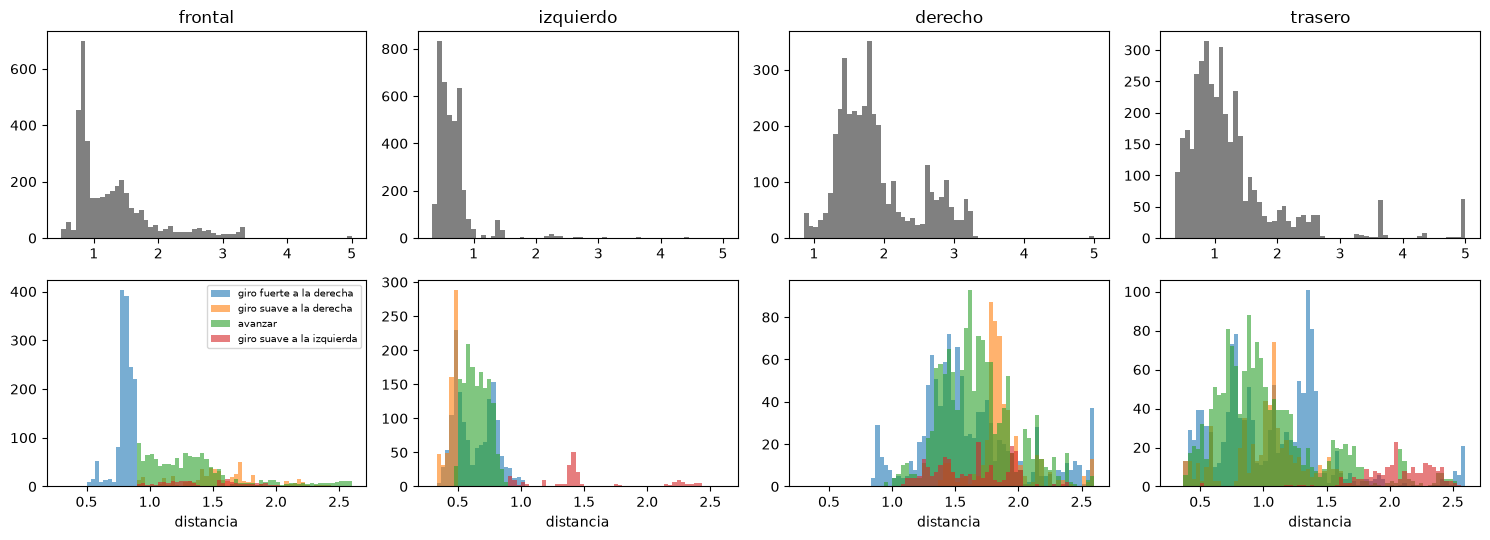

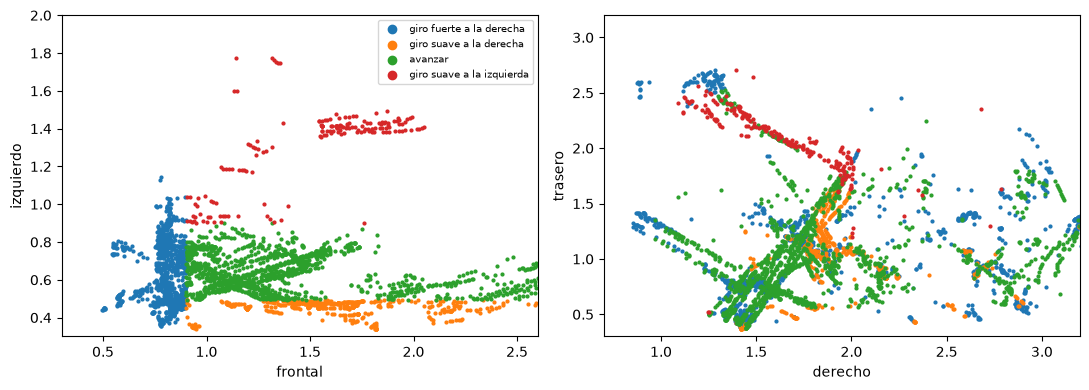

In [8]:
tr = pd.DataFrame(X4[itr], columns=SENSORES); tr["c"] = y[itr]
fig, ejes = plt.subplots(2, 4, figsize=(15, 5.5))
for k, s in enumerate(SENSORES):
    ejes[0, k].hist(tr[s], bins=60, color="0.5"); ejes[0, k].set_title(s)
    for c in range(4):
        ejes[1, k].hist(tr[s][tr.c == c], bins=np.linspace(0.3, 2.6, 70), alpha=.6, label=NOMBRES[c])
    ejes[1, k].set_xlabel("distancia")
ejes[1, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for c in range(4):
    ejes[0].scatter(tr.frontal[tr.c == c], tr.izquierdo[tr.c == c], s=4, label=NOMBRES[c])
    ejes[1].scatter(tr.derecho[tr.c == c], tr.trasero[tr.c == c], s=4)
ejes[0].set(xlabel="frontal", ylabel="izquierdo", xlim=(0.3, 2.6), ylim=(0.3, 2.0)); ejes[0].legend(fontsize=7, markerscale=3)
ejes[1].set(xlabel="derecho", ylabel="trasero", xlim=(0.7, 3.2), ylim=(0.3, 3.2))
plt.tight_layout(); plt.show()

In [9]:
print("Rango de cada sensor por clase en el entrenamiento (mínimo, mediana, máximo)")
for s in SENSORES:
    print(f"\n{s}")
    for c in range(4):
        v = tr[s][tr.c == c]
        print(f"   {NOMBRES[c]:<26} {v.min():6.3f} {v.median():6.3f} {v.max():6.3f}")

Rango de cada sensor por clase en el entrenamiento (mínimo, mediana, máximo)

frontal
   giro fuerte a la derecha    0.495  0.809  0.900
   giro suave a la derecha     0.901  1.560  5.000
   avanzar                     0.901  1.350  5.000
   giro suave a la izquierda   0.904  1.380  2.096

izquierdo
   giro fuerte a la derecha    0.354  0.609  5.000
   giro suave a la derecha     0.340  0.467  0.494
   avanzar                     0.495  0.646  0.900
   giro suave a la izquierda   0.902  1.413  3.134

derecho
   giro fuerte a la derecha    0.854  1.696  5.000
   giro suave a la derecha     1.387  1.845  5.000
   avanzar                     0.966  1.703  5.000
   giro suave a la izquierda   1.089  1.625  2.783

trasero
   giro fuerte a la derecha    0.378  1.144  5.000
   giro suave a la derecha     0.367  1.066  1.701
   avanzar                     0.374  0.941  5.000
   giro suave a la izquierda   0.519  2.109  5.000


**Qué observar.** El sensor frontal separa por completo el giro fuerte a la derecha, que solo ocurre con lecturas hasta 0.900, de las otras tres acciones, que empiezan en 0.901. Con el frente despejado, el sensor izquierdo separa las otras tres en franjas que no se tocan, giro suave a la derecha hasta 0.494, avanzar entre 0.495 y 0.900 y giro suave a la izquierda desde 0.902. Los histogramas por clase de los sensores derecho y trasero se superponen en gran parte, aunque el trasero toma valores altos sobre todo en el giro suave a la izquierda. Las acciones parecen el resultado de reglas con umbrales sobre dos distancias, lo que concuerda con el clasificador heurístico que las asignó.

## Paso 4. Funciones de pertenencia desde el análisis
Cada umbral que muestran los histogramas por clase del frontal y del izquierdo se toma como el punto medio entre el mayor valor de la clase de abajo y el menor de la clase de arriba, siempre en el entrenamiento. Ese punto medio solo vale porque las clases no se solapan, y el punto de control lo comprueba. Para el derecho y el trasero, cuyas clases sí se solapan, el corte es el valor que mejor separa las acciones con esa variable sola, el que elige un árbol de decisión de un nivel. Las etiquetas son trapecios que se cruzan en 0.5 justo en cada corte, con una transición de semiancho $\delta = 0.05$ que se fija a mano.

frontal   0.9005
izq_bajo  0.4945
izq_alto  0.9010
derecho   1.7575
trasero   1.8015
Fracción de cada acción por encima del corte del derecho: [0.45  0.881 0.432 0.348]
Fracción de cada acción por encima del corte del trasero: [0.169 0.    0.064 0.87 ]


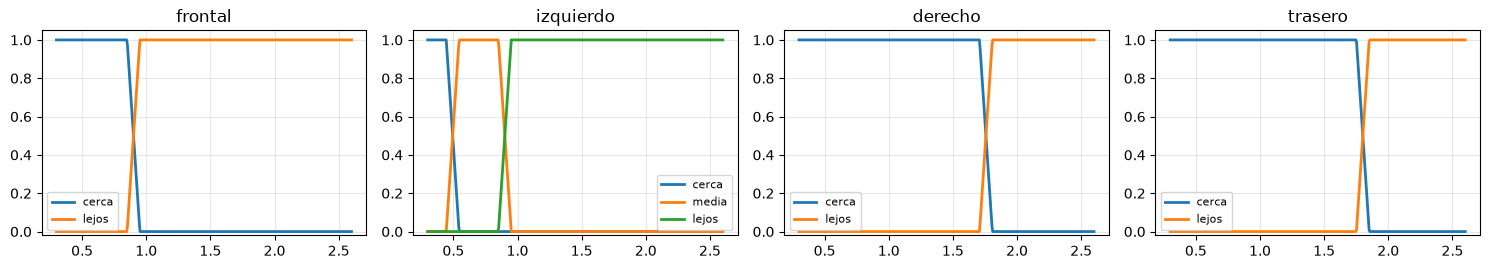

In [10]:
from sklearn.tree import DecisionTreeClassifier
def corte(abajo, arriba):
    """Punto medio entre el mayor valor del grupo de abajo y el menor del grupo de arriba."""
    return float((np.max(abajo) + np.min(arriba)) / 2)

def corte_arbol(x, y):
    """Valor que mejor separa las clases con una sola variable (árbol de un nivel)."""
    return float(DecisionTreeClassifier(max_depth=1, random_state=SEMILLA).fit(x[:, None], y).tree_.threshold[0])

DELTA = 0.05                                       # semiancho de la transición difusa
def dos_etiquetas(u, nombres=("cerca", "lejos"), delta=DELTA):
    return {nombres[0]: ("trapmf", (-1, -1, u - delta, u + delta)), nombres[1]: ("trapmf", (u - delta, u + delta, 6, 6))}

def tres_etiquetas(u1, u2, nombres=("cerca", "media", "lejos"), delta=DELTA):
    return {nombres[0]: ("trapmf", (-1, -1, u1 - delta, u1 + delta)),
            nombres[1]: ("trapmf", (u1 - delta, u1 + delta, u2 - delta, u2 + delta)),
            nombres[2]: ("trapmf", (u2 - delta, u2 + delta, 6, 6))}

def disenar_mf(Xtr, ytr, delta=DELTA):
    """Umbrales y etiquetas a partir de las clases del entrenamiento."""
    f, i, de, t = Xtr.T
    libre = ytr != 0                                # frente despejado
    u = {"frontal": corte(f[ytr == 0], f[libre]),
         "izq_bajo": corte(i[ytr == 1], i[ytr == 2]),
         "izq_alto": corte(i[ytr == 2], i[ytr == 3]),
         "derecho": corte_arbol(de, ytr), "trasero": corte_arbol(t, ytr)}
    MF = {"frontal": dos_etiquetas(u["frontal"], delta=delta),
          "izquierdo": tres_etiquetas(u["izq_bajo"], u["izq_alto"], delta=delta),
          "derecho": dos_etiquetas(u["derecho"], delta=delta),
          "trasero": dos_etiquetas(u["trasero"], delta=delta)}
    return MF, u

MF, umbral = disenar_mf(X4[itr], y[itr])
for k, v in umbral.items():
    print(f"{k:<9} {v:.4f}")
for s in ("derecho", "trasero"):
    print(f"Fracción de cada acción por encima del corte del {s}:", np.round([np.mean(tr[s][tr.c == c] > umbral[s]) for c in range(4)], 3))
fig, ejes = plt.subplots(1, 4, figsize=(15, 2.8))
xg = np.linspace(0.3, 2.6, 400)
for ax, s in zip(ejes, SENSORES):
    for e, (t, p) in MF[s].items():
        ax.plot(xg, mf(t, p, xg), lw=2, label=e)
    ax.set_title(s); ax.set_ylim(-0.02, 1.05); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [11]:
# PUNTO DE CONTROL 2
f, i = X4[itr, 0], X4[itr, 1]
verificar("En el entrenamiento el frontal separa el giro fuerte sin solaparse", f[y[itr] == 0].max() < f[y[itr] != 0].min(), "")
verificar("En el entrenamiento el izquierdo separa las otras tres clases sin solaparse",
          i[y[itr] == 1].max() < i[y[itr] == 2].min() and i[y[itr] == 2].max() < i[y[itr] == 3].min(), "")
xg = np.linspace(0.3, 5, 2001)
verificar("Las etiquetas de cada sensor suman 1 en todo el rango", all(np.allclose(sum(mf(t, p, xg) for t, p in MF[s].values()), 1) for s in SENSORES), "")
verificar("Cada umbral es un cruce en 0.5", abs(float(mf(*MF["frontal"]["cerca"], umbral["frontal"])) - 0.5) < 1e-9, "")

[OK]      En el entrenamiento el frontal separa el giro fuerte sin solaparse
[OK]      En el entrenamiento el izquierdo separa las otras tres clases sin solaparse
[OK]      Las etiquetas de cada sensor suman 1 en todo el rango
[OK]      Cada umbral es un cruce en 0.5


True

## Paso 5. Base de reglas en rejilla completa
Las reglas son todas las combinaciones de etiquetas, como pide el enunciado, de modo que el número de reglas es el producto del número de etiquetas por variable. El consecuente de cada regla se aprende del entrenamiento como en el método de Ishibuchi, Nozaki y Tanaka (1992), es la acción cuyas muestras activan más esa regla (suma de fuerzas con la t-norma producto), y la certeza es la fracción de esa suma que aporta la acción elegida. Para clasificar gana la regla más fuerte, como en el cuaderno resuelto.

In [12]:
def grados(X, variables, MF):
    """Una matriz N x n_etiquetas por variable."""
    return [np.stack([mf(t, p, X[:, k]) for t, p in MF[v].values()], axis=1) for k, v in enumerate(variables)]

def fuerza_rejilla(Gs, R):
    """Fuerza de cada regla con la t-norma producto. R: n_reglas x F índices de etiqueta."""
    fuerza = np.ones((Gs[0].shape[0], len(R)))
    for k, G in enumerate(Gs):
        fuerza *= G[:, R[:, k]]
    return fuerza

def crear_reglas(X, y, variables, MF, n_clases=4):
    """Rejilla completa. Consecuente = acción con mayor suma de fuerza; certeza = esa suma sobre el total."""
    R = np.array(list(itertools.product(*[range(len(MF[v])) for v in variables])))
    fuerza = fuerza_rejilla(grados(X, variables, MF), R)
    voto = np.stack([fuerza[y == c].sum(axis=0) for c in range(n_clases)], axis=1)
    soporte = voto.sum(axis=1)
    return R, voto.argmax(axis=1), soporte, voto.max(axis=1) / np.maximum(soporte, 1e-12)

def clasificar(X, variables, MF, R, clases):
    fuerza = fuerza_rejilla(grados(X, variables, MF), R)
    return clases[fuerza.argmax(axis=1)], fuerza

def mostrar_reglas(R, clases, soporte, certeza, variables, MF, max_reglas=None):
    etiquetas = {v: list(MF[v]) for v in variables}
    orden = np.argsort(-soporte)[:max_reglas]
    for k in orden:
        cond = " Y ".join(f"{v} es {etiquetas[v][R[k, j]]}" for j, v in enumerate(variables))
        print(f"SI {cond} ENTONCES {NOMBRES[clases[k]]}   (soporte {soporte[k]:7.1f}, certeza {certeza[k]:.3f})")

MODELOS = {"4 sensores": SENSORES, "2 sensores": SENSORES[:2]}
reglas = {}
for nombre, variables in MODELOS.items():
    k = len(variables)
    reglas[nombre] = crear_reglas(X4[itr][:, :k], y[itr], variables, MF)
    R_, c_, s_, ce_ = reglas[nombre]
    print(f"\n{nombre}: {len(R_)} reglas, {int(np.sum(s_ < 1e-9))} sin soporte, certeza mínima {ce_[s_ > 0].min():.3f}")
    mostrar_reglas(*reglas[nombre], variables, MF, max_reglas=None if k == 2 else 8)


4 sensores: 24 reglas, 0 sin soporte, certeza mínima 0.735
SI frontal es lejos Y izquierdo es media Y derecho es cerca Y trasero es cerca ENTONCES avanzar   (soporte   812.9, certeza 0.932)
SI frontal es lejos Y izquierdo es media Y derecho es lejos Y trasero es cerca ENTONCES avanzar   (soporte   713.8, certeza 0.825)
SI frontal es cerca Y izquierdo es media Y derecho es cerca Y trasero es cerca ENTONCES giro fuerte a la derecha   (soporte   471.0, certeza 0.962)
SI frontal es lejos Y izquierdo es cerca Y derecho es lejos Y trasero es cerca ENTONCES giro suave a la derecha   (soporte   434.5, certeza 0.867)
SI frontal es cerca Y izquierdo es media Y derecho es lejos Y trasero es cerca ENTONCES giro fuerte a la derecha   (soporte   335.6, certeza 0.961)
SI frontal es cerca Y izquierdo es cerca Y derecho es lejos Y trasero es cerca ENTONCES giro fuerte a la derecha   (soporte   222.8, certeza 0.977)
SI frontal es lejos Y izquierdo es lejos Y derecho es cerca Y trasero es lejos ENTONCES

In [13]:
# PUNTO DE CONTROL 3
for nombre, variables in MODELOS.items():
    verificar(f"{nombre}: no supera las 100 reglas", len(reglas[nombre][0]) <= 100, "")
R4, c4, s4, ce4 = reglas["4 sensores"]
R2, c2, s2, _ = reglas["2 sensores"]
mapa2 = {tuple(r): c for r, c in zip(R2, c2)}
distintas = np.array([k for k, r in enumerate(R4) if c4[k] != mapa2[tuple(r[:2])]], dtype=int)
print("Reglas de 4 sensores cuyo consecuente no sigue al frontal y al izquierdo:", len(distintas))
mostrar_reglas(R4[distintas], c4[distintas], s4[distintas], ce4[distintas], SENSORES, MF)
verificar("Esas reglas tienen un soporte menor que el de un solo registro", bool(np.all(s4[distintas] < 1)), "una regla con soporte alto contradiría el análisis")

[OK]      4 sensores: no supera las 100 reglas
[OK]      2 sensores: no supera las 100 reglas
Reglas de 4 sensores cuyo consecuente no sigue al frontal y al izquierdo: 2
SI frontal es lejos Y izquierdo es cerca Y derecho es lejos Y trasero es lejos ENTONCES avanzar   (soporte     0.1, certeza 1.000)
SI frontal es lejos Y izquierdo es cerca Y derecho es cerca Y trasero es lejos ENTONCES giro fuerte a la derecha   (soporte     0.0, certeza 1.000)
[OK]      Esas reglas tienen un soporte menor que el de un solo registro


True

## Paso 6. Evaluación en prueba
Además de la exactitud se informa la exactitud balanceada, el promedio del acierto de cada clase, porque el giro suave a la izquierda es solo el 6 % de los registros. Antes de mirar la prueba, la validación cruzada de 5 particiones en el entrenamiento compara los dos modelos. Después se miden una vez en prueba junto a un árbol de decisión al que se le permiten tantas hojas como reglas.

In [14]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold
pliegues = list(StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(itr, y[itr]))
cv_modelos = {}
for nombre, variables in MODELOS.items():
    k, acc = len(variables), []
    for a, b in pliegues:
        Mf, _ = disenar_mf(X4[itr[a]], y[itr[a]])
        Rv, cv_, _, _ = crear_reglas(X4[itr[a]][:, :k], y[itr[a]], variables, Mf)
        acc.append(accuracy_score(y[itr[b]], clasificar(X4[itr[b]][:, :k], variables, Mf, Rv, cv_)[0]))
    cv_modelos[nombre] = float(np.mean(acc))
    print(f"{nombre}: validación cruzada en el entrenamiento {cv_modelos[nombre]:.4f}")

resultados, matrices = {}, {}
for nombre, variables in MODELOS.items():
    k = len(variables)
    R_, c_, s_, _ = reglas[nombre]
    pred, fuerza = clasificar(X4[ite][:, :k], variables, MF, R_, c_)
    arbol = DecisionTreeClassifier(max_leaf_nodes=len(R_), random_state=SEMILLA).fit(X4[itr][:, :k], y[itr])
    resultados[nombre] = dict(reglas=len(R_), exactitud=accuracy_score(y[ite], pred), balanceada=balanced_accuracy_score(y[ite], pred),
                              arbol=accuracy_score(y[ite], arbol.predict(X4[ite][:, :k])), hojas=int(arbol.get_n_leaves()),
                              gana=np.bincount(fuerza.argmax(axis=1), minlength=len(R_)).tolist())
    matrices[nombre] = confusion_matrix(y[ite], pred, labels=range(4))
    print(f"{nombre}: {len(R_)} reglas | exactitud {resultados[nombre]['exactitud']:.4f} | balanceada {resultados[nombre]['balanceada']:.4f}"
          f" | árbol con {resultados[nombre]['hojas']} hojas {resultados[nombre]['arbol']:.4f}")
    print("   veces que gana cada regla en prueba:", resultados[nombre]["gana"])
    print(matrices[nombre])
regla_nitida = np.where(X4[:, 0] <= umbral["frontal"], 0, np.where(X4[:, 1] <= umbral["izq_bajo"], 1, np.where(X4[:, 1] <= umbral["izq_alto"], 2, 3)))
aciertos_nitida = int(np.sum(regla_nitida == y))
print("\nLa regla de tres umbrales acierta", aciertos_nitida, "de los", len(y), "registros del archivo")
solo_dt = DecisionTreeClassifier(random_state=SEMILLA).fit(X4[itr][:, 2:], y[itr])
acc_solo_dt = accuracy_score(y[ite], solo_dt.predict(X4[ite][:, 2:]))
hojas_solo_dt = int(solo_dt.get_n_leaves())
it_t0, ie_t0 = np.arange(int(0.7 * len(y))), np.arange(int(0.7 * len(y)), len(y))
solo_dt_t = DecisionTreeClassifier(random_state=SEMILLA).fit(X4[it_t0][:, 2:], y[it_t0])
acc_solo_dt_t = accuracy_score(y[ie_t0], solo_dt_t.predict(X4[ie_t0][:, 2:]))
may_t = float(np.mean(y[ie_t0] == np.bincount(y[it_t0]).argmax()))
print("Un árbol sin límite con solo el derecho y el trasero acierta %.3f en prueba con %d hojas (la clase mayoritaria es el %.3f)" % (acc_solo_dt, hojas_solo_dt, np.mean(y[ite] == 2)))
print("Con la partición temporal ese árbol acierta %.3f (la clase mayoritaria del entrenamiento es el %.3f de la prueba)" % (acc_solo_dt_t, may_t))

4 sensores: validación cruzada en el entrenamiento 1.0000
2 sensores: validación cruzada en el entrenamiento 1.0000


4 sensores: 24 reglas | exactitud 1.0000 | balanceada 1.0000 | árbol con 4 hojas 1.0000
   veces que gana cada regla en prueba: [51, 0, 98, 1, 204, 78, 136, 21, 5, 30, 5, 0, 30, 0, 218, 0, 347, 45, 260, 10, 0, 58, 11, 29]
[[629   0   0   0]
 [  0 248   0   0]
 [  0   0 662   0]
 [  0   0   0  98]]
2 sensores: 6 reglas | exactitud 1.0000 | balanceada 1.0000 | árbol con 4 hojas 1.0000
   veces que gana cada regla en prueba: [150, 439, 40, 248, 662, 98]
[[629   0   0   0]
 [  0 248   0   0]
 [  0   0 662   0]
 [  0   0   0  98]]

La regla de tres umbrales acierta 5456 de los 5456 registros del archivo


Un árbol sin límite con solo el derecho y el trasero acierta 0.751 en prueba con 959 hojas (la clase mayoritaria es el 0.404)
Con la partición temporal ese árbol acierta 0.651 (la clase mayoritaria del entrenamiento es el 0.409 de la prueba)


**Punto de comparación.** El clasificador del cuaderno resuelto reparte etiquetas uniformes entre el mínimo y el máximo del entrenamiento y da a cada regla la clase del registro de mayor grado. Para separar el efecto de la ubicación de las etiquetas del efecto del método de reglas, se comparan cuatro variantes con el límite de 100 reglas. Las etiquetas pueden ser uniformes entre el mínimo y el máximo o de igual frecuencia, repartidas según los cuantiles del entrenamiento. El consecuente puede salir del registro de mayor grado, como en el cuaderno resuelto, o de la suma de fuerzas, como en el modelo propio. En cada variante el número de etiquetas se elige con validación cruzada en el entrenamiento.

In [15]:
# ===== Análisis adicional: particiones uniformes con el límite de 100 reglas =====
def escala(Xa, modo):
    """Devuelve una función que lleva las lecturas a [0, 1] con el mínimo y el máximo o con los cuantiles del entrenamiento."""
    if modo == "mínimo y máximo":
        lo, hi = Xa.min(0), Xa.max(0)
        return lambda Z: normalizar(Z, lo, hi)
    orden = np.sort(Xa, axis=0)
    return lambda Z: np.stack([np.searchsorted(orden[:, j], Z[:, j], side="right") / len(orden) for j in range(Z.shape[1])], axis=1)

def ajustar_uniforme(Xa, ya, n, metodo):
    if metodo == "registro de mayor grado":
        Rn, cn, _ = extraer_reglas(Xa, ya, n)
        return Rn, cn
    Rn = np.array(list(itertools.product(*[range(n)] * Xa.shape[1])))
    fz = grados_pertenencia(Xa, n)[:, np.arange(Xa.shape[1])[None, :], Rn].prod(axis=2)
    voto = np.stack([fz[ya == c].sum(axis=0) for c in range(4)], axis=1)
    return Rn, voto.argmax(axis=1)

uniforme = []
for k in (4, 2):
    ns = [n for n in range(2, 11) if n ** k <= 100]
    for modo in ("mínimo y máximo", "cuantiles"):
        for metodo in ("registro de mayor grado", "suma de fuerzas"):
            cv = {}
            for n in ns:
                acc = []
                for a, b in pliegues:
                    esc = escala(X4[itr[a]][:, :k], modo)
                    Rn, cn = ajustar_uniforme(esc(X4[itr[a]][:, :k]), y[itr[a]], n, metodo)
                    acc.append(accuracy_score(y[itr[b]], predecir_reglas(esc(X4[itr[b]][:, :k]), Rn, cn, n)[0]))
                cv[n] = float(np.mean(acc))
            n = max(cv, key=cv.get)
            esc = escala(X4[itr][:, :k], modo)
            Rn, cn = ajustar_uniforme(esc(X4[itr][:, :k]), y[itr], n, metodo)
            pn = predecir_reglas(esc(X4[ite][:, :k]), Rn, cn, n)[0]
            uniforme.append(dict(sensores=k, escala=modo, metodo=metodo, n=n, rejilla=n ** k, reglas=len(Rn), cv=cv,
                                 exactitud=accuracy_score(y[ite], pn), balanceada=balanced_accuracy_score(y[ite], pn),
                                 avanzar=int(np.sum((pn == 2) & (y[ite] == 2)))))
            print(f"{k} sensores, {modo}, {metodo}: n = {n} ({len(Rn)} reglas) | validación {cv[n]:.3f} | prueba {uniforme[-1]['exactitud']:.4f}"
                  f" | balanceada {uniforme[-1]['balanceada']:.4f} | avanzar acierta {uniforme[-1]['avanzar']} de {int(np.sum(y[ite] == 2))}")
esc = escala(X4[itr][:, :2], "mínimo y máximo"); n6 = next(u["n"] for u in uniforme if u["sensores"] == 2 and u["escala"] == "mínimo y máximo" and u["metodo"] == "registro de mayor grado")
Rn, cn, _ = extraer_reglas(esc(X4[itr][:, :2]), y[itr], n6)
_, fz = predecir_reglas(esc(X4[ite][:, :2]), Rn, cn, n6)
gana_av = np.bincount(fz.argmax(axis=1)[y[ite] == 2], minlength=len(Rn)).argmax()
dominante = grados_pertenencia(esc(X4[itr][:, :2]), n6).argmax(axis=2)
en_celda = (dominante == Rn[gana_av]).all(axis=1)
celda_mezcla = np.bincount(y[itr][en_celda], minlength=4).tolist()
print(f"\nCuaderno resuelto con n = {n6}: la regla que más registros de avanzar decide en prueba dice {NOMBRES[cn[gana_av]]}.")
print("En el entrenamiento su celda reúne, por acción:", dict(zip(NOMBRES, celda_mezcla)))
av_celda = int(np.bincount(fz.argmax(axis=1)[y[ite] == 2], minlength=len(Rn)).max())
print("Esa regla decide", av_celda, "de los", int(np.sum(y[ite] == 2)), "registros de avanzar de prueba")
print("\nCon el mínimo y el máximo del entrenamiento, 0.495 y 0.900 del sensor izquierdo quedan en",
      np.round(normalizar(np.array([[0.495], [0.900]]), X4[itr, 1].min(), X4[itr, 1].max()).ravel(), 3), "de la escala [0, 1]")

4 sensores, mínimo y máximo, registro de mayor grado: n = 3 (16 reglas) | validación 0.465 | prueba 0.4502 | balanceada 0.3570 | avanzar acierta 3 de 662
4 sensores, mínimo y máximo, suma de fuerzas: n = 3 (81 reglas) | validación 0.520 | prueba 0.5040 | balanceada 0.3652 | avanzar acierta 182 de 662


4 sensores, cuantiles, registro de mayor grado: n = 3 (72 reglas) | validación 0.828 | prueba 0.8424 | balanceada 0.8868 | avanzar acierta 584 de 662
4 sensores, cuantiles, suma de fuerzas: n = 3 (81 reglas) | validación 0.871 | prueba 0.8839 | balanceada 0.9126 | avanzar acierta 630 de 662


2 sensores, mínimo y máximo, registro de mayor grado: n = 6 (15 reglas) | validación 0.594 | prueba 0.5925 | balanceada 0.7362 | avanzar acierta 7 de 662
2 sensores, mínimo y máximo, suma de fuerzas: n = 7 (49 reglas) | validación 0.781 | prueba 0.7923 | balanceada 0.5974 | avanzar acierta 615 de 662


2 sensores, cuantiles, registro de mayor grado: n = 10 (97 reglas) | validación 0.976 | prueba 0.9780 | balanceada 0.9473 | avanzar acierta 644 de 662
2 sensores, cuantiles, suma de fuerzas: n = 10 (100 reglas) | validación 0.973 | prueba 0.9695 | balanceada 0.9376 | avanzar acierta 637 de 662



Cuaderno resuelto con n = 6: la regla que más registros de avanzar decide en prueba dice giro suave a la derecha.
En el entrenamiento su celda reúne, por acción: {'giro fuerte a la derecha': 0, 'giro suave a la derecha': 430, 'avanzar': 1003, 'giro suave a la izquierda': 0}
Esa regla decide 418 de los 662 registros de avanzar de prueba

Con el mínimo y el máximo del entrenamiento, 0.495 y 0.900 del sensor izquierdo quedan en [0.033 0.12 ] de la escala [0, 1]


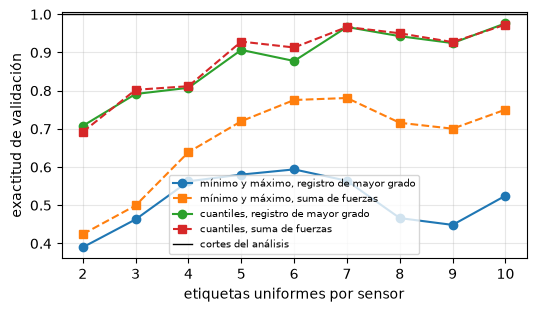

[OK]      El modelo de 2 sensores no pierde exactitud frente al de 4
[OK]      Las funciones del análisis superan a todas las particiones uniformes
[OK]      Las matrices suman el número de registros de prueba


True

In [16]:
plt.figure(figsize=(6, 3.2))
for u in uniforme:
    if u["sensores"] == 2:
        plt.plot(sorted(u["cv"]), [u["cv"][n] for n in sorted(u["cv"])], "o-" if u["metodo"].startswith("registro") else "s--", label=f"{u['escala']}, {u['metodo']}")
plt.axhline(cv_modelos["2 sensores"], color="k", lw=1, label="cortes del análisis")
plt.xlabel("etiquetas uniformes por sensor"); plt.ylabel("exactitud de validación"); plt.grid(alpha=.3); plt.legend(fontsize=7); plt.show()

# PUNTO DE CONTROL 4
verificar("El modelo de 2 sensores no pierde exactitud frente al de 4", resultados["2 sensores"]["exactitud"] >= resultados["4 sensores"]["exactitud"] - 1e-12, "")
verificar("Las funciones del análisis superan a todas las particiones uniformes", resultados["2 sensores"]["exactitud"] > max(u["exactitud"] for u in uniforme), "")
verificar("Las matrices suman el número de registros de prueba", all(m.sum() == len(ite) for m in matrices.values()), "")

## Paso 7. Análisis adicional
Qué tanto depende el resultado de dónde se pongan los umbrales y del ancho de la transición difusa, cuándo compite de verdad otra acción, qué pasa si las lecturas tienen ruido, qué aporta una salida continua de tipo Sugeno y si la partición aleatoria es demasiado optimista para datos que vienen de un recorrido continuo.

Exactitud en prueba al mover cada umbral (de -0.10 a +0.10):
   frontal   0.787 0.822 0.853 0.893 0.913 0.930 0.953 0.968 0.980 0.987 1.000 0.992 0.981 0.974 0.965 0.958 0.954 0.949 0.939 0.932 0.927
   izq_bajo  0.864 0.864 0.864 0.872 0.876 0.880 0.891 0.909 0.931 0.971 1.000 0.984 0.970 0.956 0.945 0.938 0.925 0.913 0.903 0.885 0.870
   izq_alto  0.977 0.981 0.984 0.988 0.990 0.993 0.994 0.996 0.997 0.998 1.000 0.999 0.998 0.998 0.994 0.993 0.992 0.992 0.992 0.991 0.991


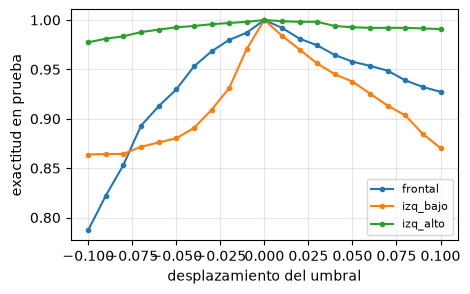

Registros de prueba a menos de 0.01 del umbral frontal: 21 por debajo y 13 por encima

semiancho  exactitud  registros con regla ganadora < 1  certeza mínima
    0.001     1.0000      0.011      0.997
    0.010     1.0000      0.111      0.968
    0.050     1.0000      0.409      0.842
    0.100     1.0000      0.632      0.686
    0.200     1.0000      0.946      0.493

Con semiancho 0.05, 40.9 % de los registros de prueba cae en una franja de transición.
En 30.2 % compite una regla de otra acción y en 10.7 % solo reglas de la misma acción.


In [17]:
# ===== Análisis adicional: umbrales, ancho de la transición y competencia entre acciones =====
R2, c2, _, _ = reglas["2 sensores"]
desplazamientos = np.round(np.arange(-0.10, 0.1001, 0.01), 2)
sens = {"frontal": [], "izq_bajo": [], "izq_alto": []}
for clave in sens:
    for dlt in desplazamientos:
        u = dict(umbral); u[clave] += dlt
        MFd = {"frontal": dos_etiquetas(u["frontal"]), "izquierdo": tres_etiquetas(u["izq_bajo"], u["izq_alto"])}
        p, _ = clasificar(X4[ite][:, :2], SENSORES[:2], MFd, R2, c2)
        sens[clave].append(accuracy_score(y[ite], p))
print("Exactitud en prueba al mover cada umbral (de -0.10 a +0.10):")
for clave, v in sens.items():
    print(f"   {clave:<9}", " ".join(f"{a:.3f}" for a in v))
plt.figure(figsize=(5, 3))
for clave, v in sens.items():
    plt.plot(desplazamientos, v, "o-", ms=3, label=clave)
plt.xlabel("desplazamiento del umbral"); plt.ylabel("exactitud en prueba"); plt.grid(alpha=.3); plt.legend(fontsize=8); plt.show()
fte = X4[ite, 0]
cerca_abajo = int(np.sum((fte > umbral["frontal"] - 0.01) & (fte <= umbral["frontal"])))
cerca_arriba = int(np.sum((fte > umbral["frontal"]) & (fte < umbral["frontal"] + 0.01)))
print("Registros de prueba a menos de 0.01 del umbral frontal: %d por debajo y %d por encima" % (cerca_abajo, cerca_arriba))

anchos = (0.001, 0.01, 0.05, 0.10, 0.20)
ancho = []
for dl in anchos:
    MFa, _ = disenar_mf(X4[itr], y[itr], delta=dl)
    Ra, ca, _, cea = crear_reglas(X4[itr][:, :2], y[itr], SENSORES[:2], MFa)
    p, fz = clasificar(X4[ite][:, :2], SENSORES[:2], MFa, Ra, ca)
    ancho.append((dl, accuracy_score(y[ite], p), float(np.mean(fz.max(axis=1) < 1)), float(cea.min())))
print("\nsemiancho  exactitud  registros con regla ganadora < 1  certeza mínima")
for dl, a, fr, ce in ancho:
    print(f"{dl:>9.3f} {a:>10.4f} {fr:>10.3f} {ce:>10.3f}")

p2, fz2 = clasificar(X4[ite][:, :2], SENSORES[:2], MF, R2, c2)
rival = np.array([fz2[k][c2 != c2[fz2[k].argmax()]].max() for k in range(len(ite))])
en_franja = fz2.max(axis=1) < 1
print("\nCon semiancho 0.05, %.1f %% de los registros de prueba cae en una franja de transición." % (100 * en_franja.mean()))
print("En %.1f %% compite una regla de otra acción y en %.1f %% solo reglas de la misma acción." % (100 * np.mean(rival > 0), 100 * np.mean(en_franja & (rival == 0))))

ruido   difuso (media, mínimo, máximo de 20)   árbol (media)   menor fracción de predicciones iguales
0.005   0.9872   0.9841   0.9914       0.9872      1.000
0.010   0.9726   0.9664   0.9786       0.9726      1.000
0.020   0.9467   0.9407   0.9597       0.9467      1.000
0.050   0.8775   0.8693   0.8882       0.8775      1.000

Sugeno de orden cero redondeado a la acción más cercana: exactitud 0.9511
Registros de prueba con giro intermedio (no entero): 495
Errores del redondeo: 80 | en la franja del umbral frontal: 80 | se predicen como: {'giro suave a la derecha': 77, 'avanzar': 3}
Con -3 para el giro fuerte la exactitud al redondear es 0.9585


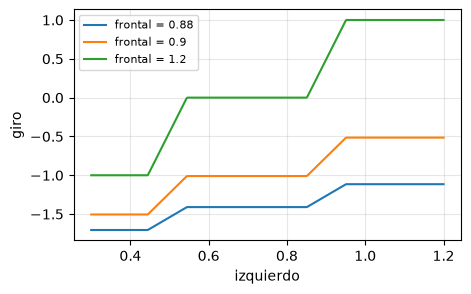

In [18]:
# ===== Análisis adicional: ruido en las lecturas y salida de tipo Sugeno =====
rng = np.random.default_rng(SEMILLA)
arbol2 = DecisionTreeClassifier(random_state=SEMILLA).fit(X4[itr][:, :2], y[itr])
ruido = []
for sigma in (0.005, 0.01, 0.02, 0.05):
    af, aa, ig = [], [], []
    for _ in range(20):                               # 20 realizaciones del ruido
        Xr = X4[ite][:, :2] + rng.normal(0, sigma, size=(len(ite), 2))
        pf, _ = clasificar(Xr, SENSORES[:2], MF, R2, c2)
        pa = arbol2.predict(Xr)
        af.append(accuracy_score(y[ite], pf)); aa.append(accuracy_score(y[ite], pa)); ig.append(np.mean(pf == pa))
    ruido.append((sigma, float(np.mean(af)), float(np.min(af)), float(np.max(af)), float(np.mean(aa)), float(np.min(ig))))
print("ruido   difuso (media, mínimo, máximo de 20)   árbol (media)   menor fracción de predicciones iguales")
for s_, a, lo, hi, b, c in ruido:
    print(f"{s_:>5.3f} {a:>8.4f} {lo:>8.4f} {hi:>8.4f} {b:>12.4f} {c:>10.3f}")

GIRO = np.array([-2.0, -1.0, 0.0, 1.0])            # giro fuerte der., giro suave der., avanzar, giro suave izq.
def sugeno0(X):
    """Las seis reglas como Sugeno de orden cero: salida = suma de w z / suma de w, con z el giro de cada acción."""
    w = fuerza_rejilla(grados(X, SENSORES[:2], MF), R2)
    return (w * GIRO[c2]).sum(axis=1) / w.sum(axis=1)
giro = sugeno0(X4[ite][:, :2])
pred_giro = np.abs(giro[:, None] - GIRO[None, :]).argmin(axis=1)
print("\nSugeno de orden cero redondeado a la acción más cercana: exactitud %.4f" % accuracy_score(y[ite], pred_giro))
print("Registros de prueba con giro intermedio (no entero):", int(np.sum(np.abs(giro - np.round(giro)) > 1e-9)))
mal = pred_giro != y[ite]
franja_f = np.abs(X4[ite, 0] - umbral["frontal"]) < DELTA
print("Errores del redondeo:", int(mal.sum()), "| en la franja del umbral frontal:", int((mal & franja_f).sum()),
      "| se predicen como:", {NOMBRES[k]: int(np.sum(pred_giro[mal] == k)) for k in range(4) if np.sum(pred_giro[mal] == k)})
GIRO_B = np.array([-3.0, -1.0, 0.0, 1.0])
w = fuerza_rejilla(grados(X4[ite][:, :2], SENSORES[:2], MF), R2)
giro_b = (w * GIRO_B[c2]).sum(axis=1) / w.sum(axis=1)
acc_sugeno_b = accuracy_score(y[ite], np.abs(giro_b[:, None] - GIRO_B[None, :]).argmin(axis=1))
print("Con -3 para el giro fuerte la exactitud al redondear es %.4f" % acc_sugeno_b)
xs = np.linspace(0.3, 1.2, 400)
plt.figure(figsize=(5, 3))
for fr in (0.88, 0.90, 1.2):
    plt.plot(xs, sugeno0(np.column_stack([np.full_like(xs, fr), xs])), label=f"frontal = {fr}")
plt.xlabel("izquierdo"); plt.ylabel("giro"); plt.grid(alpha=.3); plt.legend(fontsize=8); plt.show()

In [19]:
# ===== Análisis adicional: partición temporal =====
corte_t = int(0.7 * len(y))
it_t, ie_t = np.arange(corte_t), np.arange(corte_t, len(y))
MFt, ut = disenar_mf(X4[it_t], y[it_t])
temporal = {}
for nombre, variables in MODELOS.items():
    k = len(variables)
    Rt, ct, _, _ = crear_reglas(X4[it_t][:, :k], y[it_t], variables, MFt)
    p, _ = clasificar(X4[ie_t][:, :k], variables, MFt, Rt, ct)
    temporal[nombre] = (accuracy_score(y[ie_t], p), balanced_accuracy_score(y[ie_t], p))
print("Partición temporal (primer 70 % del recorrido para entrenar, último 30 % para probar):")
print("   cortes", {k: round(v, 4) for k, v in ut.items()})
for nombre, (a, b) in temporal.items():
    print(f"   {nombre}: exactitud {a:.4f} | balanceada {b:.4f}")

Partición temporal (primer 70 % del recorrido para entrenar, último 30 % para probar):
   cortes {'frontal': 0.9005, 'izq_bajo': 0.4945, 'izq_alto': 0.901, 'derecho': 1.7565, 'trasero': 1.2715}
   4 sensores: exactitud 1.0000 | balanceada 1.0000
   2 sensores: exactitud 1.0000 | balanceada 1.0000


## Paso 8. Modelos entregados
Los dos modelos se guardan en `modelos/` como archivos JSON con los cortes, las etiquetas, las reglas y sus consecuentes. El modelo recomendado es el de dos sensores. La última celda los vuelve a cargar desde disco y clasifica los archivos de prueba de `particiones/`, sin usar nada de lo calculado antes.

In [20]:
os.makedirs("modelos", exist_ok=True)
for nombre, variables in MODELOS.items():
    R_, c_, s_, ce_ = reglas[nombre]
    modelo = {"variables": variables, "tnorma": "producto", "decision": "regla más fuerte", "semiancho": DELTA,
              "cortes": {k: round(float(v), 4) for k, v in umbral.items() if (k.startswith("izq") and "izquierdo" in variables) or k in variables},
              "etiquetas": {v: {e: {"tipo": t, "parametros": list(map(float, p))} for e, (t, p) in MF[v].items()} for v in variables},
              "acciones": CLASES,
              "reglas": [{"si": {v: list(MF[v])[R_[j, k]] for k, v in enumerate(variables)}, "entonces": CLASES[c_[j]],
                          "soporte": round(float(s_[j]), 4), "certeza": round(float(ce_[j]), 4)} for j in range(len(R_))]}
    json.dump(modelo, open(f"modelos/modelo_{nombre.replace(' ', '_')}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print(sorted(os.listdir("modelos")))

['modelo_2_sensores.json', 'modelo_4_sensores.json']


In [21]:
def cargar_modelo(ruta):
    """Lee un modelo JSON y devuelve una función que clasifica una tabla con las columnas de sus variables."""
    m = json.load(open(ruta, encoding="utf-8"))
    def clasificar_tabla(tabla):
        fuerza = np.ones((len(tabla), len(m["reglas"])))
        for j, regla in enumerate(m["reglas"]):
            for v, e in regla["si"].items():
                et = m["etiquetas"][v][e]
                fuerza[:, j] *= mf(et["tipo"], et["parametros"], tabla[v].to_numpy())
        return np.array([m["reglas"][j]["entonces"] for j in fuerza.argmax(axis=1)])
    return m, clasificar_tabla

# PUNTO DE CONTROL 8
for k, nombre in ((2, "2_sensores"), (4, "4_sensores")):
    m, clasificar_tabla = cargar_modelo(f"modelos/modelo_{nombre}.json")
    prueba = pd.read_csv(f"particiones/aleatoria_prueba_{k}_sensores.csv")
    pred = clasificar_tabla(prueba)
    print(f"Modelo de {k} sensores leído de disco: {len(m['reglas'])} reglas, exactitud en prueba {np.mean(pred == prueba['accion']):.4f}")
    verificar(f"El modelo de {k} sensores guardado reproduce las predicciones", np.mean(pred == prueba["accion"]) == resultados[f"{k} sensores"]["exactitud"], "")

Modelo de 2 sensores leído de disco: 6 reglas, exactitud en prueba 1.0000
[OK]      El modelo de 2 sensores guardado reproduce las predicciones
Modelo de 4 sensores leído de disco: 24 reglas, exactitud en prueba 1.0000
[OK]      El modelo de 4 sensores guardado reproduce las predicciones


## Paso 9. Resultados para el informe
Se guardan en `resultados.json` las cifras que usa el informe. Con ese archivo, el guion `figuras_informe.py` vuelve a generar las figuras del informe en `figuras/` y sus cifras en `cifras.tex`.

In [22]:
# ---- Resultados que usan las figuras y las cifras del informe (figuras_informe.py) ----
lista = lambda a: np.asarray(a).tolist()
reglas_informe = {}
for nombre, variables in MODELOS.items():
    R_, c_, s_, ce_ = reglas[nombre]
    _, fuerza = clasificar(X4[ite][:, :len(variables)], variables, MF, R_, c_)
    reglas_informe[nombre] = dict(R=lista(R_), c=lista(c_), soporte=lista(s_), certeza=lista(ce_),
                                  gana=lista(np.bincount(fuerza.argmax(axis=1), minlength=len(R_))), fuerza_max=lista(fuerza.max(axis=1)))
informe = dict(
    n=len(y), n_tr=len(itr), n_te=len(ite), conteo=lista(np.bincount(y)), conteo_te=lista(np.bincount(y[ite])), itr=lista(itr), ite=lista(ite),
    saturadas={s: int((d4[s] >= 5).sum()) for s in SENSORES}, saturadas_tr={s: int((tr[s] >= 5).sum()) for s in SENSORES},
    cambio_med=lista(np.median(np.abs(np.diff(X4, axis=0)), axis=0)), cambio_accion=float(np.mean(y[1:] != y[:-1])),
    rangos={s: [[float(tr[s][tr.c == c].min()), float(tr[s][tr.c == c].median()), float(tr[s][tr.c == c].max())] for c in range(4)] for s in SENSORES},
    umbral=umbral, delta=DELTA, arriba={s: [float(np.mean(tr[s][tr.c == c] > umbral[s])) for c in range(4)] for s in ("derecho", "trasero")},
    MF={s: {e: [t, list(p)] for e, (t, p) in MF[s].items()} for s in SENSORES},
    reglas=reglas_informe, distintas=lista(distintas), resultados=resultados, matrices={k: lista(v) for k, v in matrices.items()},
    cv_modelos=cv_modelos, aciertos_nitida=aciertos_nitida, acc_solo_dt=float(acc_solo_dt), mayoritaria=float(np.mean(y[ite] == 2)),
    uniforme=[{k: ({str(a): b for a, b in v.items()} if isinstance(v, dict) else v) for k, v in u.items()} for u in uniforme],
    celda_mezcla=celda_mezcla, av_celda=av_celda, hojas_solo_dt=hojas_solo_dt, acc_solo_dt_t=float(acc_solo_dt_t), may_t=may_t,
    errores_sugeno=int(mal.sum()), errores_franja_f=int((mal & franja_f).sum()), errores_a_suave=int(np.sum(pred_giro[mal] == 1)),
    acc_sugeno=float(accuracy_score(y[ite], pred_giro)), acc_sugeno_b=float(acc_sugeno_b),
    n_intermedio=int(np.sum(np.abs(giro - np.round(giro)) > 1e-9)),
    escala_izq=lista(normalizar(np.array([[0.495], [0.900]]), X4[itr, 1].min(), X4[itr, 1].max()).ravel()),
    desplazamientos=lista(desplazamientos), sens=sens, cerca_abajo=cerca_abajo, cerca_arriba=cerca_arriba,
    ancho=[list(map(float, a)) for a in ancho], en_franja=float(en_franja.mean()), compite=float(np.mean(rival > 0)),
    misma=float(np.mean(en_franja & (rival == 0))), n_compite=int(np.sum(rival > 0)),
    ruido=[list(map(float, r)) for r in ruido], temporal=temporal, umbral_t=ut)
json.dump(informe, open("resultados.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=float)
print("resultados.json guardado")

resultados.json guardado
